# Identificación exploratoria de ambientes de manejo en maíz para silo forrajero

## Fusión multisensor SAOCOM–Sentinel-2

**Establecimiento La Rosaura, Tandil, Argentina**

**Trabajo final — Ciencia de Datos II**

Este estudio analiza los lotes L15 y L16 utilizando observaciones
satelitales históricas de 2024–2025.

El cultivo de maíz para silo y su cosecha durante febrero de 2025
constituyen supuestos agronómicos aportados para el estudio,
no verificaciones realizadas con datos de campo.

**Alcance:** prueba de concepto metodológica.
No se dispone de rendimiento, suelo ni validación agronómica.

**Autor:** Lautaro Ghezan  
**Asignatura:** Ciencia de Datos II


## Construcción de la constelación virtual SAOCOM–Sentinel-2

En este proyecto, una constelación virtual se entiende como
la integración analítica de observaciones procedentes de
sistemas satelitales independientes, sin modificar sus
órbitas, operaciones ni infraestructura física.

La constelación virtual SAOCOM–Sentinel-2 se construye
mediante las siguientes etapas:

1. **Selección territorial:** delimitación de los lotes
   piloto L15 y L16 del establecimiento La Rosaura.
2. **Adquisición multisensor:** incorporación de
   observaciones ópticas Sentinel-2 y radar SAOCOM.
3. **Armonización espacial:** reproyección a EPSG:32721
   y organización sobre una grilla analítica común
   de 44 x 44 metros.
4. **Armonización temporal:** asociación de observaciones
   mediante una ventana de emparejamiento de +/- 5 días.
5. **Integración de atributos:** combinación de los
   índices ópticos NDVI, NDRE y NDMI con las variables
   radar disponibles.
6. **Evaluación:** comparación de agrupamientos
   ópticos y multisensor y cuantificación de
   oportunidades adicionales de observación.

Esta construcción es una arquitectura de integración
de datos y no una constelación física nueva. Tampoco
implica cobertura diaria continua ni equivalencia entre
las mediciones ópticas y radar.

La complementariedad temporal se evidencia en 294
observaciones radar celda-fecha sin pareja óptica
válida dentro de la ventana de emparejamiento.
Sin embargo, los resultados no demuestran una mejora
agronómica independiente en la delimitación de
ambientes de manejo.


## Contexto productivo y seleccion de lotes

### El establecimiento La Rosaura

La Rosaura es un establecimiento agropecuario ubicado en el
partido de Tandil, provincia de Buenos Aires, Argentina,
vinculado a la actividad tambera.

Su sistema productivo comprende superficies destinadas a
pasturas y al cultivo de maiz para la elaboracion de silo
forrajero, utilizado como alimento para el rodeo lechero.

En este contexto, conocer la variabilidad espacial de los
cultivos puede contribuir al desarrollo futuro de herramientas
de agricultura de precision y apoyo a las decisiones de manejo.

### Identificacion de los lotes

Para el analisis territorial se consideran 16 lotes del
establecimiento, identificados como L01 a L16.

Los lotes constituyen las unidades espaciales de referencia
para organizar la informacion satelital. No deben confundirse
con los ambientes de manejo, que son agrupamientos exploratorios
identificados dentro de cada lote.

### Seleccion de L15 y L16

Del conjunto de lotes se seleccionaron L15 y L16 como casos
piloto del estudio, asociados al cultivo de maiz destinado
a silo forrajero durante la campaña 2024-2025.

Esta asociacion y la cosecha prevista durante febrero de 2025
son antecedentes agronomicos aportados al estudio; no fueron
verificados con registros de campo independientes.

La seleccion de estos lotes no constituye una muestra
estadistica representativa de los 16 lotes del establecimiento.
Tampoco se dispone de evidencia para afirmar que su seleccion
respondio a un criterio agronomico comparativo formal.

### Vinculacion con el problema de Ciencia de Datos

El proyecto explora si la integracion de observaciones
opticas Sentinel-2 y radar SAOCOM permite caracterizar
patrones espaciales y temporales dentro de los lotes piloto.

Se aplican tecnicas de aprendizaje no supervisado para
identificar agrupamientos espectrales y radar, y modelos
supervisados para estudiar la reproducibilidad de esas
pseudoetiquetas.

Los agrupamientos no equivalen a ambientes productivos
validados. Para una aplicacion agronomica operativa se
requeririan mediciones independientes de rendimiento,
suelo, biomasa y manejo, entre otras.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

RAIZ = Path.cwd()
if not (RAIZ / "data").exists():
    RAIZ = RAIZ.parent

DATOS = RAIZ / "data/processed"
TABLAS = RAIZ / "reports/tables"
FIGURAS = RAIZ / "reports/figures"

print("Directorio del proyecto:", RAIZ)

Directorio del proyecto: C:\Users\Usuario\OneDrive\Documentos\ml-saocom-sentinel-la-rosaura


## 1. Objetivo y estrategia metodológica

Se comparan agrupamientos exploratorios construidos con:

- Sentinel-2: medianas y desviaciones estándar de NDVI, NDRE y NDMI.
- SAOCOM: medianas y desviaciones estándar de HH, HV, VH y VV.

La integración espacial utiliza una grilla común de 44 metros.
El emparejamiento temporal admite una diferencia máxima de cinco días.

Las amplitudes radar se transformaron provisionalmente mediante
20 log10(amplitud). No se verificó su calibración radiométrica absoluta.

Los agrupamientos no constituyen etiquetas de productividad observada.

In [2]:
datos = pd.read_csv(
    DATOS / "clusters_intralote_L15_L16.csv"
)

print("Dimensiones:", datos.shape)
display(datos.groupby("lote_id").size().rename("celdas").to_frame())

display(
    pd.crosstab(
        datos["lote_id"],
        datos["cluster_optico_intralote"]
    )
)

Dimensiones: (107, 34)


,celdas
lote_id,
L15,52
L16,55


cluster_optico_intralote,1,2
lote_id,,
L15,15,37
L16,49,6


## 2. Agrupamiento no supervisado

Se aplicó KMeans por lote, comparando variables ópticas y
multisensor. La selección de k se basó en la silueta óptica.

La concordancia de etiquetas se evaluó con ARI y alineación
de etiquetas. La coincidencia entre modelos no representa
validación agronómica.

,lote_id,modelo,k,silueta,davies_bouldin,tamano_minimo
0,L15,Optico,2,0.442972,1.004093,15
1,L15,Optico,3,0.393299,0.889159,9
2,L15,Optico,4,0.411167,0.785525,7
3,L15,Multisensor,2,0.253133,1.739410,16
4,L15,Multisensor,3,0.191614,1.620699,9
5,L15,Multisensor,4,0.182563,1.483222,3
6,L16,Optico,2,0.579542,0.726434,6
7,L16,Optico,3,0.285881,1.056193,6
8,L16,Optico,4,0.320904,0.955238,3
9,L16,Multisensor,2,0.422954,1.110292,6


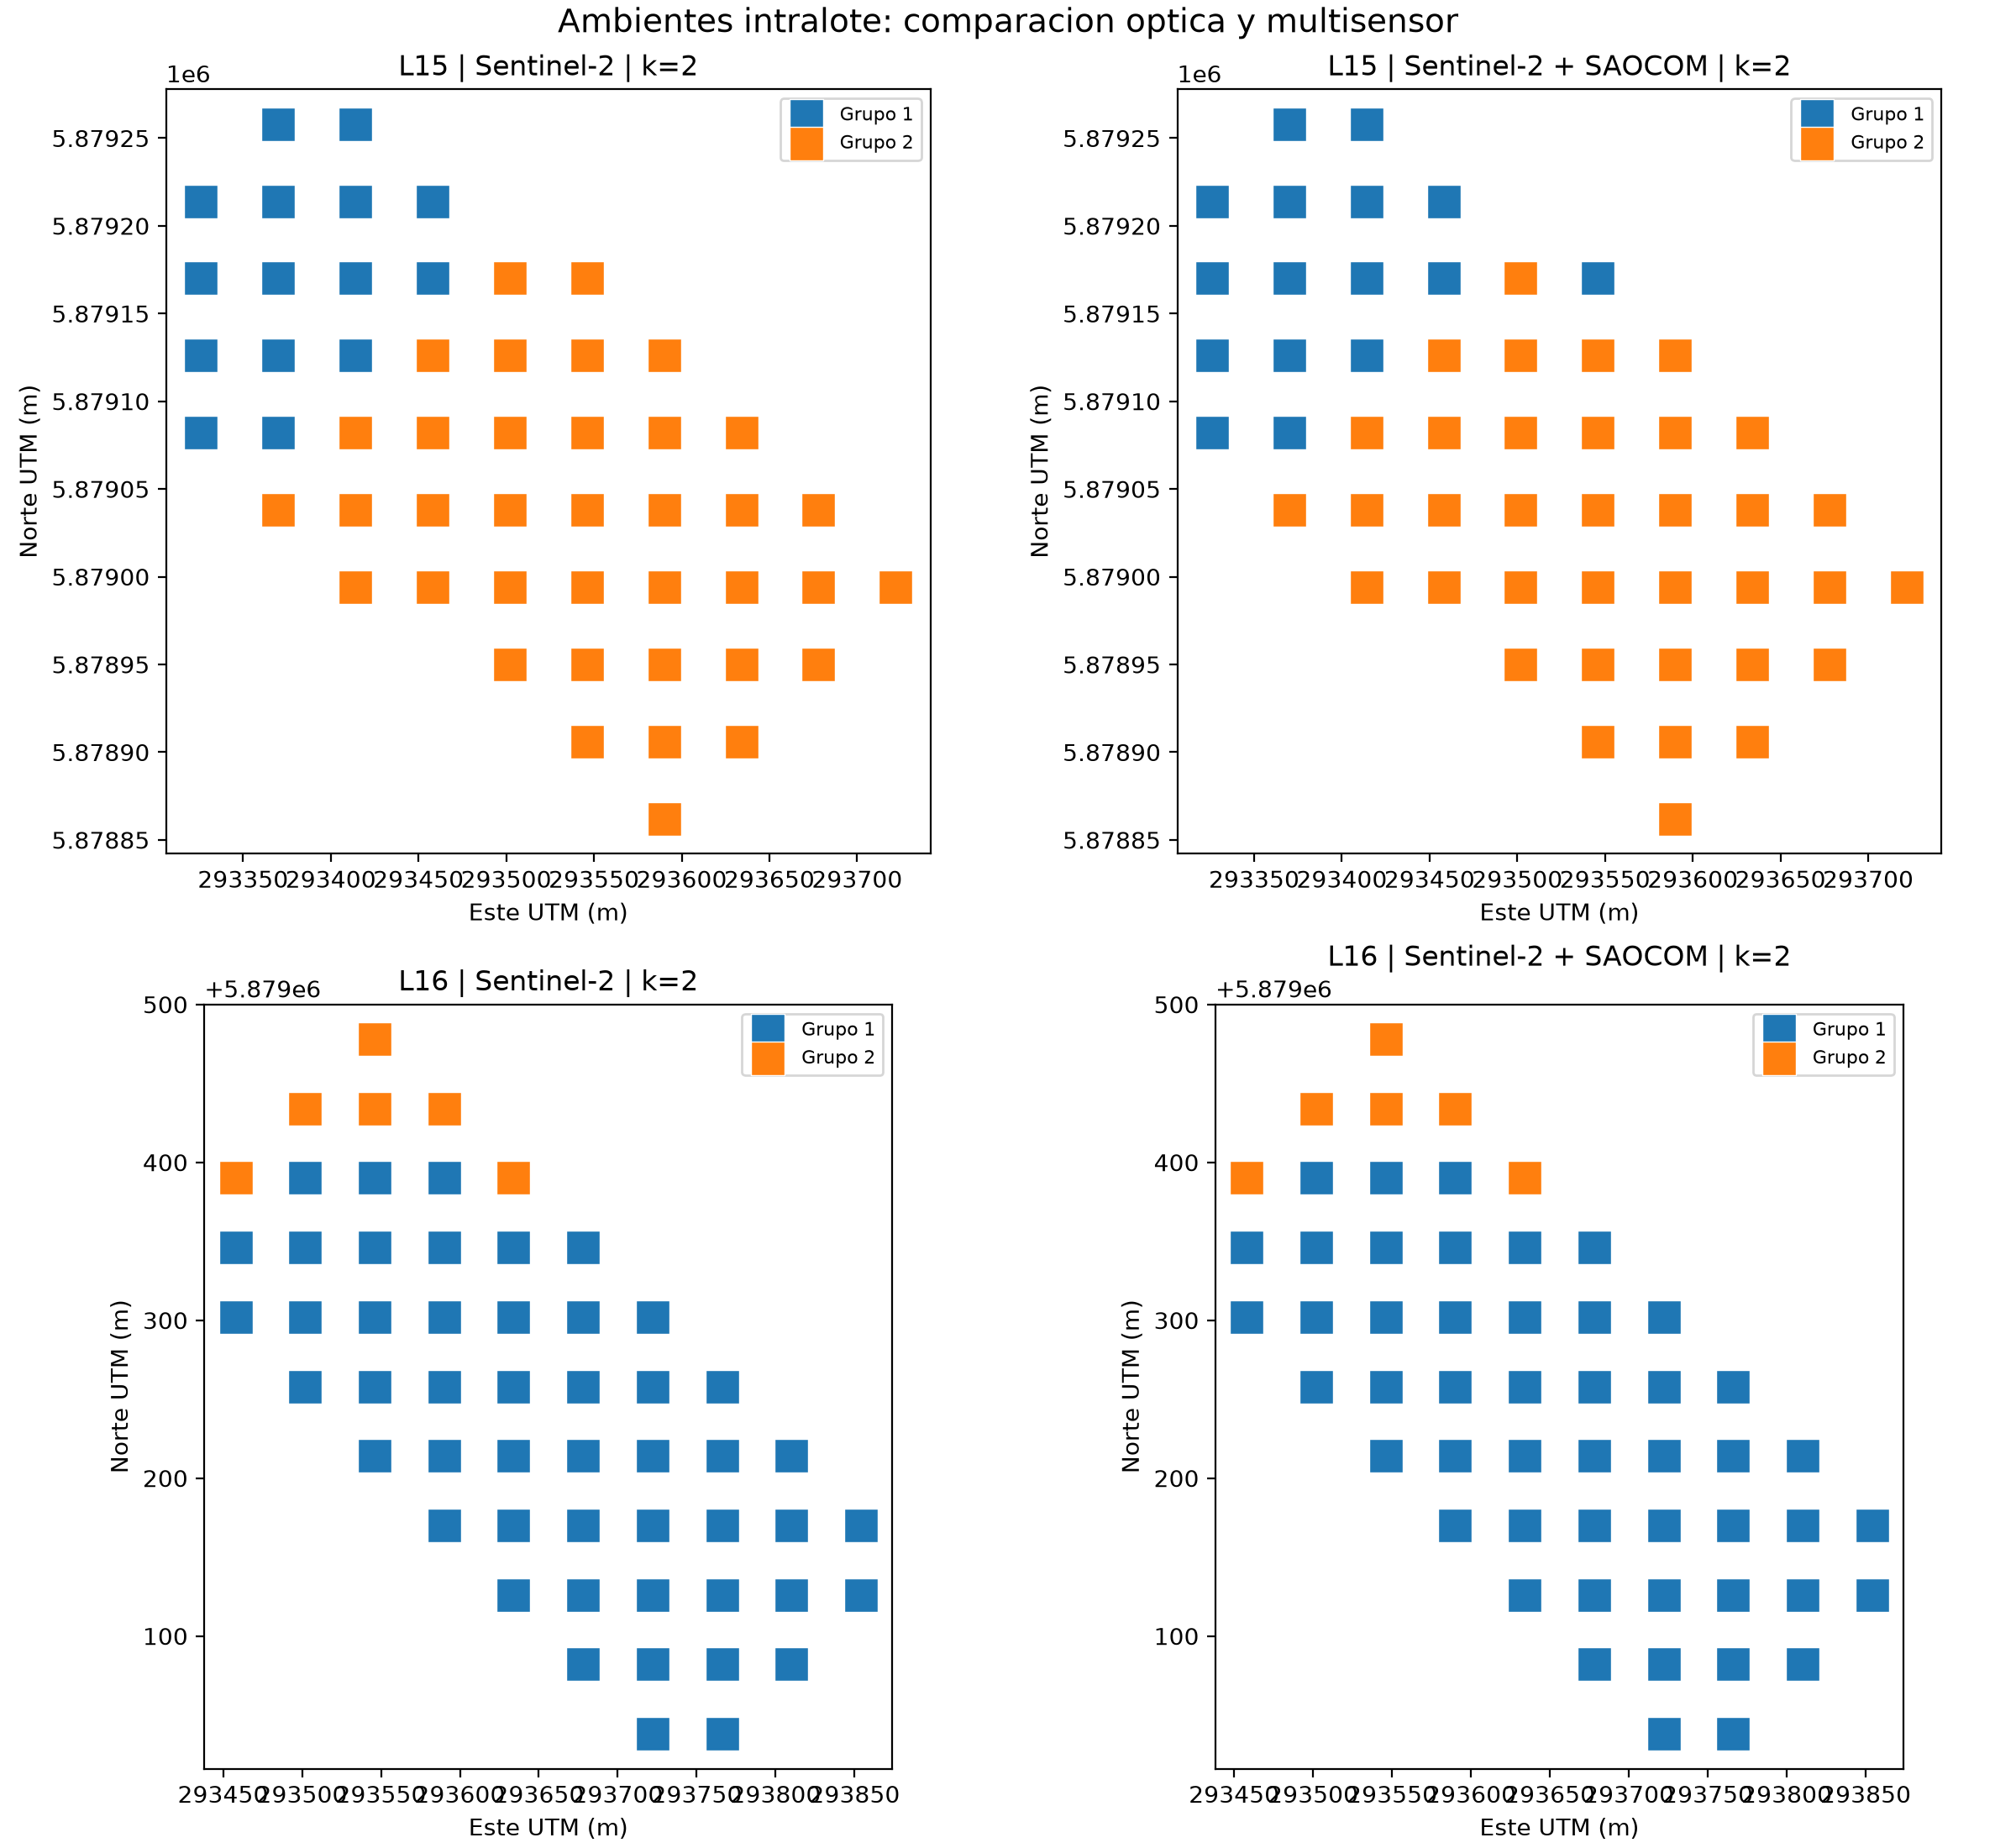

In [3]:
metricas = pd.read_csv(
    TABLAS / "metricas_clustering_intralote.csv"
)
display(metricas)

figura = FIGURAS / "clustering_intralote_L15_L16.png"
if figura.exists():
    display(Image(filename=str(figura)))

## 3. Robustez

Se analizaron cambios de semillas, exclusión individual de
atributos y exclusión de fechas de adquisición.

Estos análisis evalúan sensibilidad interna, pero no
estabilidad interanual ni transferencia a campañas futuras.

In [4]:
for archivo in [
    "robustez_clustering_intralote_L15_L16.csv",
    "robustez_temporal_clustering_L15_L16.csv"
]:
    print("\n", archivo)
    display(pd.read_csv(TABLAS / archivo))


 robustez_clustering_intralote_L15_L16.csv


,lote_id,modelo,prueba,detalle,ari
0,L15,Optico,semilla,0,1.00000
1,L15,Optico,semilla,1,1.00000
2,L15,Optico,semilla,2,1.00000
3,L15,Optico,semilla,3,1.00000
4,L15,Optico,semilla,4,1.00000
...,...,...,...,...,...
155,L16,Multisensor,omitir_atributo,HV_db_std,1.00000
156,L16,Multisensor,omitir_atributo,VH_db_mediana,1.00000
157,L16,Multisensor,omitir_atributo,VH_db_std,0.74594
158,L16,Multisensor,omitir_atributo,VV_db_mediana,0.74594



 robustez_temporal_clustering_L15_L16.csv


,lote_id,modelo,fecha_omitida,ari_vs_original,ari_vs_base_recalculada,celdas,estado
0,L15,Optico,2024-08-06,0.921397,0.921397,52,ok
1,L15,Optico,2024-09-07,0.707823,0.707823,52,ok
2,L15,Optico,2024-09-23,1.000000,1.000000,52,ok
3,L15,Optico,2024-10-09,1.000000,1.000000,52,ok
4,L15,Optico,2024-11-10,1.000000,1.000000,52,ok
5,L15,Optico,2024-12-12,0.707823,0.707823,52,ok
6,L15,Optico,2024-12-28,0.775467,0.775467,52,ok
7,L15,Optico,2025-01-13,0.447920,0.447920,52,ok
8,L15,Optico,2025-01-29,0.707823,0.707823,52,ok
9,L15,Optico,2025-02-14,1.000000,1.000000,52,ok


## 4. Clasificación supervisada de pseudoetiquetas

Se entrenaron clasificadores para reproducir las etiquetas
obtenidas mediante clustering.

Se realizaron pruebas de validación cruzada y optimización
anidada de hiperparámetros.

**Advertencia:** las pseudoetiquetas fueron obtenidas con
las mismas celdas y familias de atributos. Los resultados
no estiman capacidad predictiva sobre productividad real.

In [5]:
for archivo in [
    "metricas_supervisado_baseline_L15_L16.csv",
    "resumen_optimizacion_anidada_L15_L16.csv"
]:
    print("\n", archivo)
    display(pd.read_csv(TABLAS / archivo))


 metricas_supervisado_baseline_L15_L16.csv


,lote_id,modelo_datos,clasificador,balanced_accuracy_media,balanced_accuracy_std,f1_macro_media,f1_macro_std
0,L15,Optico,Regresion_logistica,1.000000,0.000000,1.000000,0.000000
1,L15,Optico,Random_Forest,1.000000,0.000000,1.000000,0.000000
2,L15,Optico,HistGradientBoosting,0.975983,0.050185,0.971416,0.046233
3,L15,Multisensor,Regresion_logistica,0.941111,0.051502,0.934027,0.053772
4,L15,Multisensor,Random_Forest,0.966111,0.043511,0.967926,0.041785
5,L15,Multisensor,HistGradientBoosting,0.994444,0.020787,0.991414,0.032125
6,L16,Optico,Regresion_logistica,1.000000,0.000000,1.000000,0.000000
7,L16,Optico,Random_Forest,0.962623,0.084018,0.960339,0.067954
8,L16,Optico,HistGradientBoosting,0.875123,0.155698,0.875424,0.148685
9,L16,Multisensor,Regresion_logistica,1.000000,0.000000,1.000000,0.000000



 resumen_optimizacion_anidada_L15_L16.csv


,lote_id,datos,clasificador,BA_media,BA_std,F1_media,F1_std
0,L15,Multisensor,Random_Forest,0.956,0.049,0.955,0.054
1,L15,Multisensor,Regresion_logistica,0.956,0.058,0.954,0.057
2,L15,Optico,Random_Forest,1.000,0.000,1.000,0.000
3,L15,Optico,Regresion_logistica,1.000,0.000,1.000,0.000
4,L16,Multisensor,Random_Forest,0.875,0.137,0.909,0.100
5,L16,Multisensor,Regresion_logistica,0.875,0.209,0.881,0.214
6,L16,Optico,Random_Forest,0.943,0.098,0.917,0.095
7,L16,Optico,Regresion_logistica,0.990,0.024,0.967,0.081


## 5. Sensibilidad a particiones espaciales

Se reservaron franjas espaciales completas para evaluar
la reproducción de pseudoetiquetas.

Las orientaciones se seleccionaron después de inspeccionar
la distribución de clases. Por ello, los resultados son
exploratorios y no una validación espacial independiente
preespecificada.

La comparación utiliza el mismo objetivo y las mismas
particiones para los modelos óptico y multisensor.

In [6]:
espacial = pd.read_csv(
    TABLAS / "resumen_comparacion_espacial_L15_L16.csv"
)
display(espacial)

comparacion = espacial.pivot_table(
    index=["lote_id", "objetivo"],
    columns="datos",
    values="BA_media"
)

comparacion["diferencia_multisensor"] = (
    comparacion["Multisensor"] - comparacion["Optico"]
)

display(comparacion.round(3))

,lote_id,objetivo,datos,folds,BA_media,F1_media,errores_totales,evaluaciones
0,L15,Etiquetas_multisensor,Multisensor,2,0.834416,0.693651,10,43
1,L15,Etiquetas_multisensor,Optico,2,0.982143,0.968013,1,43
2,L15,Etiquetas_opticas,Multisensor,2,0.854021,0.759976,8,43
3,L15,Etiquetas_opticas,Optico,2,1.000000,1.000000,0,43
4,L16,Etiquetas_multisensor,Multisensor,2,1.000000,1.000000,0,43
5,L16,Etiquetas_multisensor,Optico,2,1.000000,1.000000,0,43
6,L16,Etiquetas_opticas,Multisensor,2,1.000000,1.000000,0,43
7,L16,Etiquetas_opticas,Optico,2,1.000000,1.000000,0,43


datos                          Multisensor  Optico  diferencia_multisensor
lote_id objetivo                                                          
L15     Etiquetas_multisensor        0.834   0.982                  -0.148
        Etiquetas_opticas            0.854   1.000                  -0.146
L16     Etiquetas_multisensor        1.000   1.000                   0.000
        Etiquetas_opticas            1.000   1.000                   0.000

## 6. Complementariedad temporal

La complementariedad observacional se cuantifica contando
fechas con al menos una celda válida por sensor y
observaciones radar sin pareja óptica válida en ±5 días.

Estas métricas no representan cobertura espacial completa,
ni permiten atribuir todos los vacíos ópticos a nubosidad.
Los sensores tampoco miden variables intercambiables.

In [7]:
temporal = pd.read_csv(
    TABLAS / "resumen_complementariedad_temporal_L15_L16.csv"
)
detalle = pd.read_csv(
    TABLAS / "complementariedad_temporal_por_fecha_L15_L16.csv"
)

display(temporal)
display(detalle)

print(
    "Observaciones celda-fecha solo radar:",
    int(detalle["solo_radar"].sum())
)

,lote_id,fechas_opticas_validas,fechas_radar_validas,fechas_union,fechas_adicionales_radar
0,L15,33,13,45,12
1,L16,34,13,46,12


,lote_id,fecha_saocom,radar_validas,con_optico_cercano,solo_radar
0,L15,2024-08-06,52,35,17
1,L15,2024-09-07,52,52,0
2,L15,2024-09-23,52,52,0
3,L15,2024-10-09,52,52,0
4,L15,2024-10-25,52,0,52
5,L15,2024-11-10,52,52,0
6,L15,2024-12-12,52,52,0
7,L15,2024-12-28,52,52,0
8,L15,2025-01-13,52,36,16
9,L15,2025-01-29,52,52,0


Observaciones celda-fecha solo radar: 294


## 7. Explicabilidad SHAP

Se utiliza SHAP para interpretar regresiones logísticas
ajustadas a las pseudoetiquetas ópticas.

La importancia media absoluta describe contribuciones
a la salida del modelo. No implica causalidad, relevancia
agronómica ni mejora predictiva independiente.


 L15 Optico


,variable,importancia_shap
0,NDRE_mediana,1.099883
1,NDVI_mediana,1.065051
2,NDMI_std,0.805959
3,NDMI_mediana,0.785595
4,NDVI_std,0.191800
5,NDRE_std,0.118080


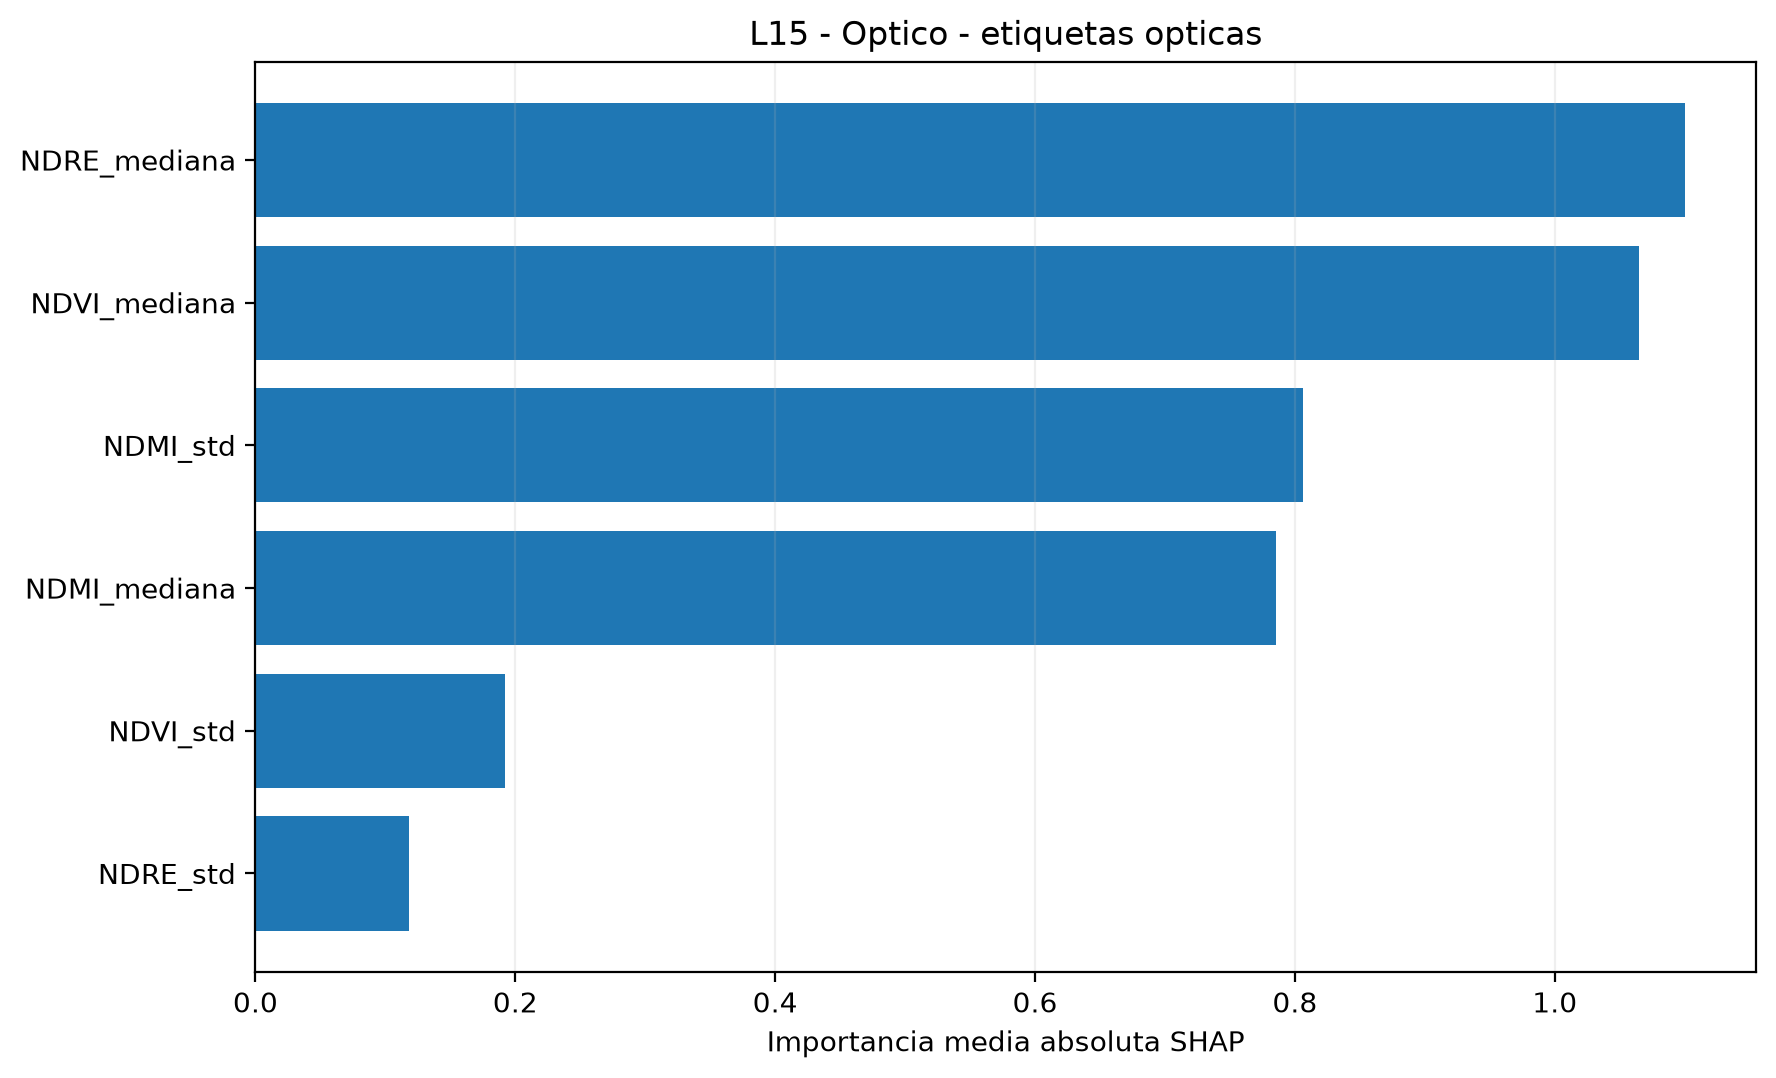


 L15 Multisensor


,variable,importancia_shap
6,NDRE_mediana,1.084113
7,NDVI_mediana,1.018734
8,NDMI_mediana,0.793629
9,NDMI_std,0.729717
10,NDVI_std,0.222259
11,HV_db_mediana,0.208954
12,VV_db_std,0.168004
13,NDRE_std,0.119946


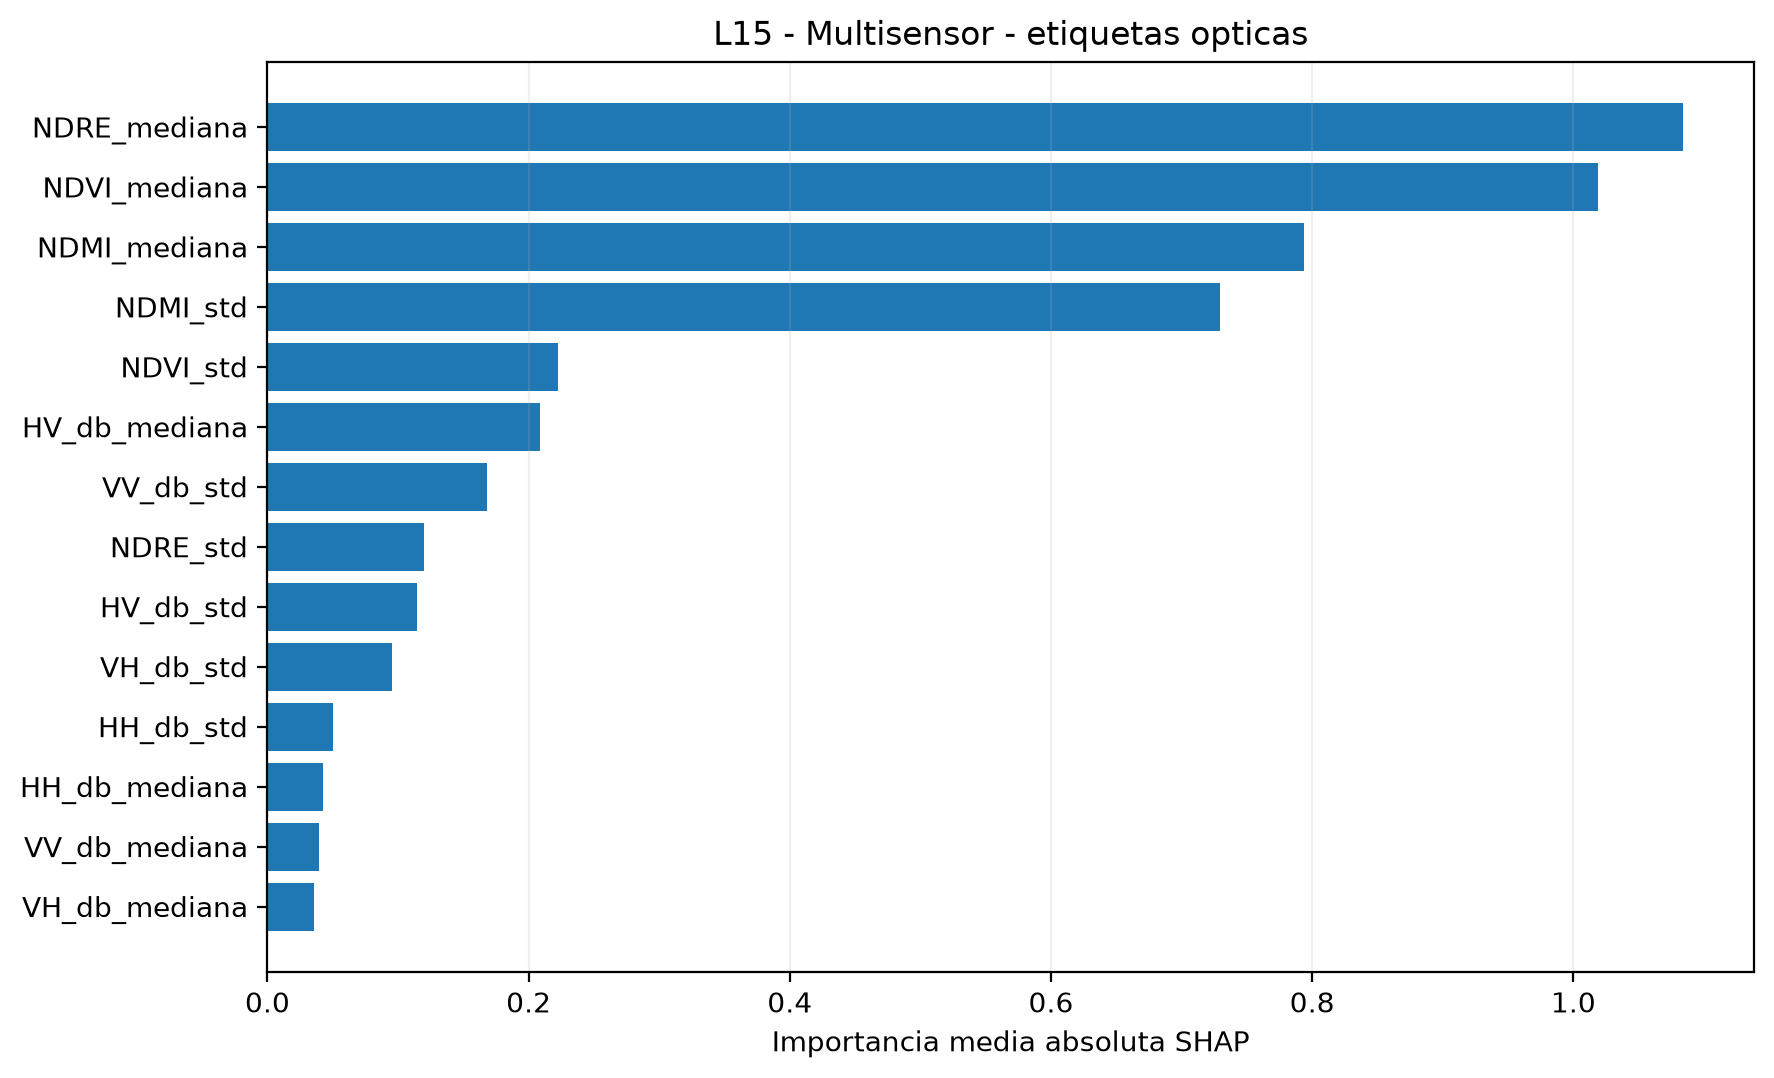


 L16 Optico


,variable,importancia_shap
20,NDMI_std,0.890885
21,NDMI_mediana,0.813357
22,NDVI_std,0.642152
23,NDVI_mediana,0.544531
24,NDRE_std,0.463546
25,NDRE_mediana,0.058195


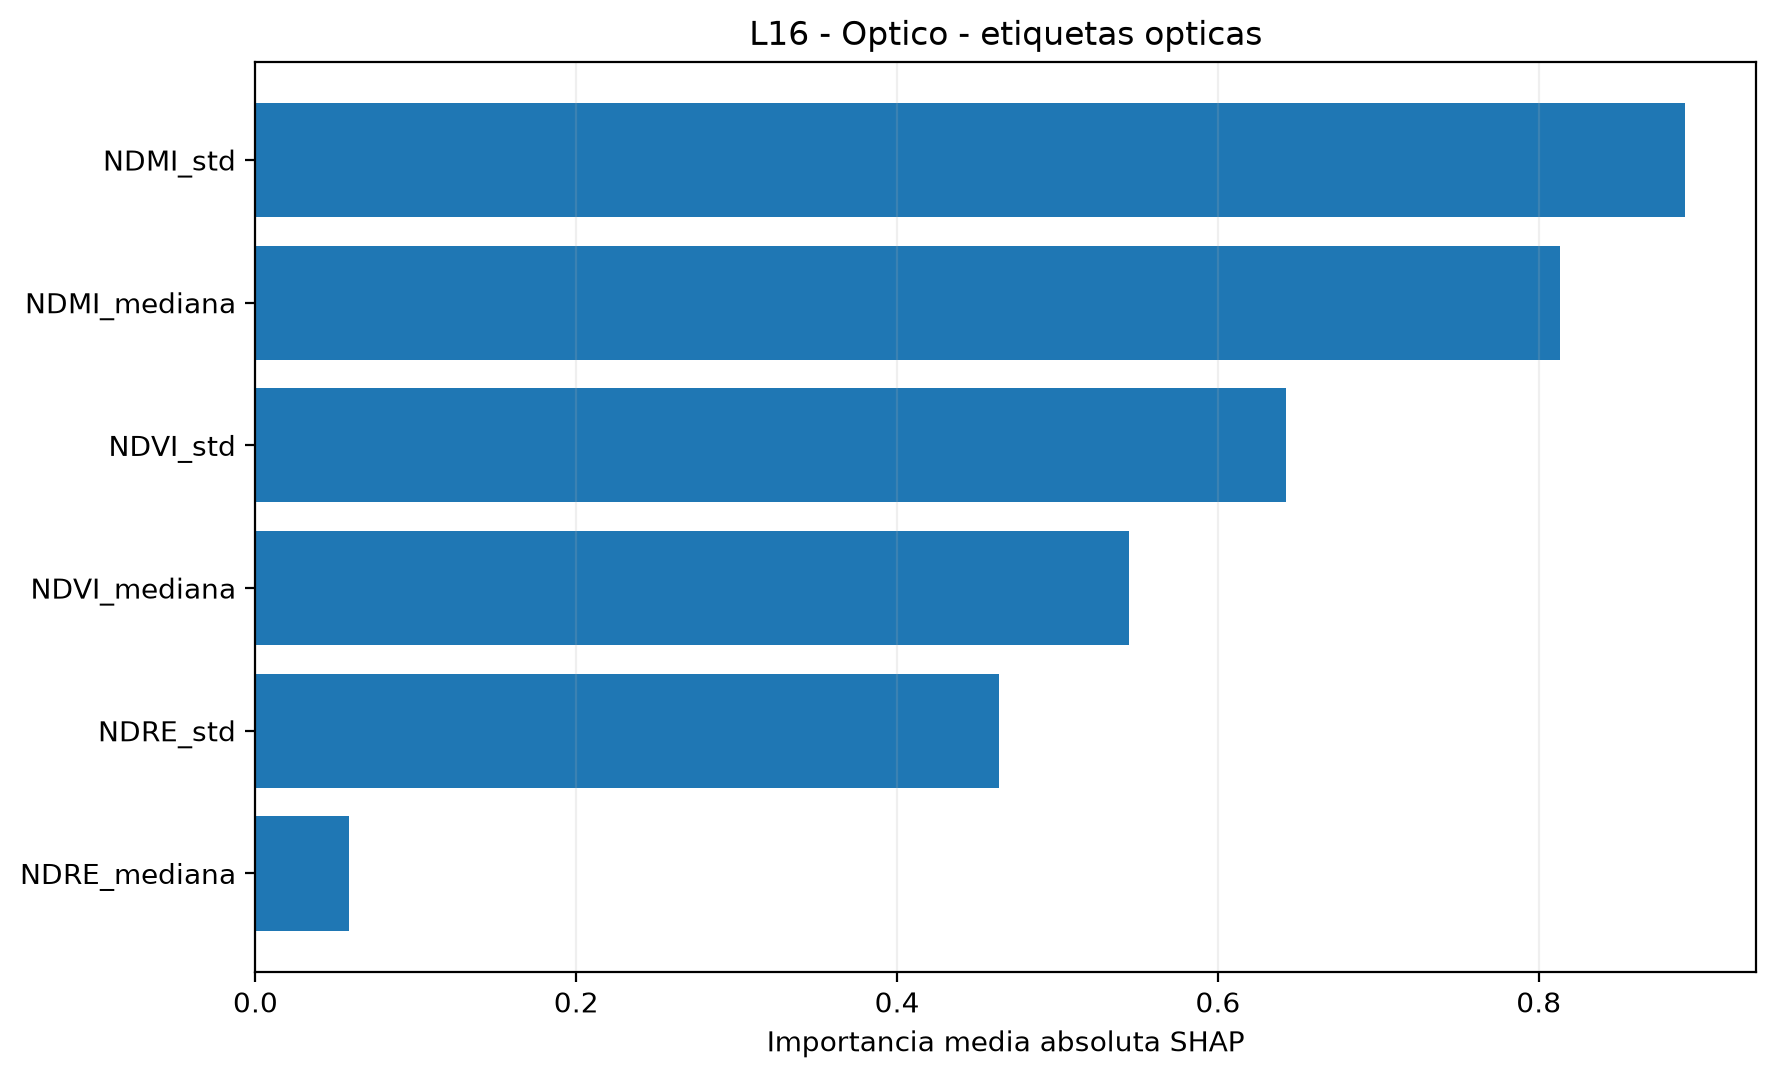


 L16 Multisensor


,variable,importancia_shap
26,NDMI_std,0.680785
27,NDMI_mediana,0.661349
28,NDVI_std,0.501967
29,NDVI_mediana,0.425577
30,NDRE_std,0.390518
31,VV_db_mediana,0.378120
32,HH_db_std,0.343532
33,HH_db_mediana,0.298583


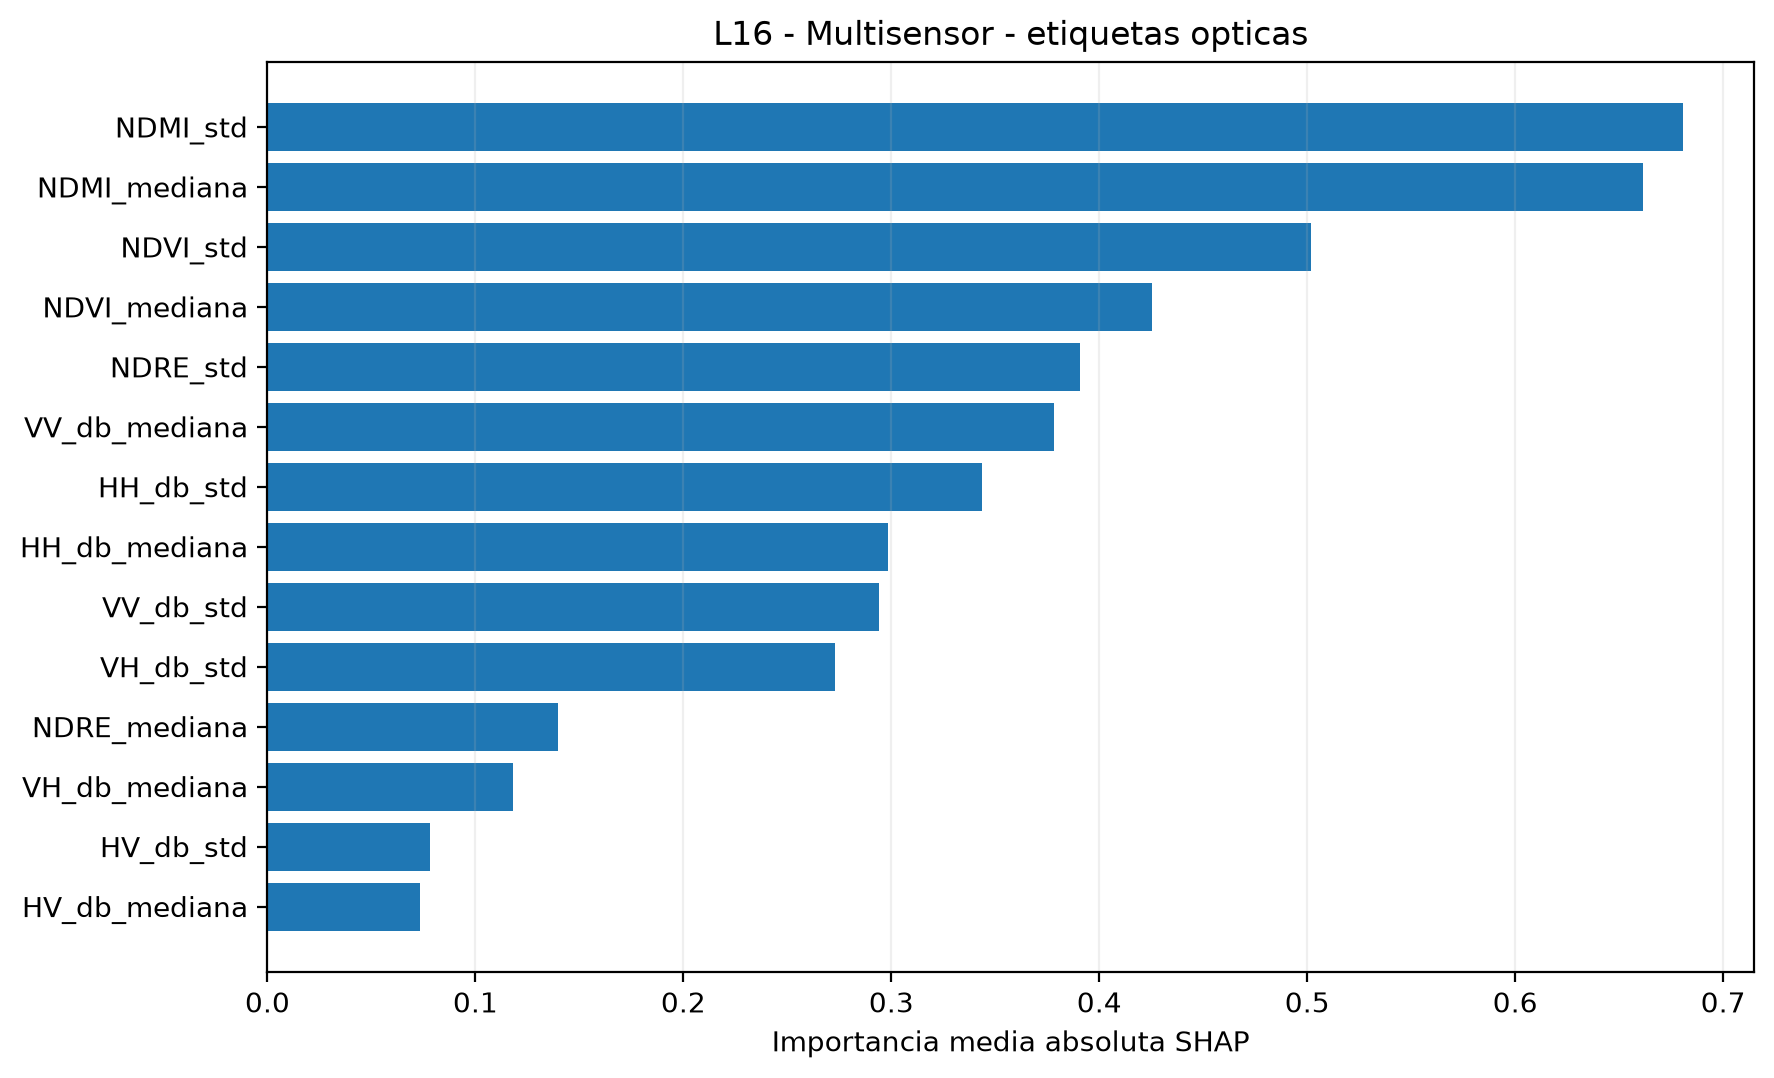

In [8]:
importancia = pd.read_csv(
    TABLAS / "importancia_shap_L15_L16.csv"
)

for lote in ["L15", "L16"]:
    for modelo in ["Optico", "Multisensor"]:
        print("\n", lote, modelo)
        tabla = importancia[
            (importancia["lote_id"] == lote)
            & (importancia["modelo"] == modelo)
        ]
        display(
            tabla[
                ["variable", "importancia_shap"]
            ].head(8)
        )

        figura = (
            FIGURAS / f"shap_{lote}_{modelo.lower()}.png"
        )
        if figura.exists():
            display(Image(filename=str(figura)))

## 8. Conclusiones

**H1 — Complementariedad observacional:** respaldada
descriptivamente por fechas y observaciones radar adicionales.

**H2 — Complementariedad informacional:** se identifican
diferencias entre las señales ópticas y radar, sin demostrar
una mejora agronómica.

**H3 — Mejora de delimitación de ambientes:** no demostrada.
En las particiones espaciales evaluables, la regresión logística
multisensor no superó a la óptica.

**H4 — Estabilidad interanual:** pendiente de evaluación
con nuevas campañas y datos de campo.

### Limitaciones

- Dos lotes y 107 celdas espaciales en total.
- Pseudoetiquetas sin verdad de terreno independiente.
- Dependencia espacial y temporal entre observaciones.
- Clases minoritarias con pocos ejemplos.
- Calibración radar absoluta no verificada.
- Ausencia de datos de rendimiento, suelo y manejo.
- No se demuestra estabilidad entre campañas.

### Perspectiva

La constelación virtual presenta una ventaja observacional
cuantificable, pero su traducción en decisiones de agricultura
de precisión requiere validación agronómica independiente.

## 9. Pipeline reproducible de Machine Learning

Esta sección reproduce directamente los experimentos principales de clasificación.

**Variable objetivo:** pseudoetiquetas ópticas obtenidas mediante KMeans.

Se entrenan modelos independientes para L15 y L16, porque los agrupamientos
fueron definidos separadamente para cada lote.

**Métrica principal:** exactitud balanceada.
**Métrica complementaria:** F1 macro.

Las pseudoetiquetas se generaron previamente utilizando todas las celdas.
Por ello, los resultados de clasificación evalúan la reproducción de
agrupamientos exploratorios y no la capacidad predictiva agronómica
independiente.

Se comparan dos conjuntos de variables sobre el mismo objetivo:
óptico y multisensor.


In [9]:
from sklearn.model_selection import (
    RepeatedStratifiedKFold, StratifiedKFold,
    GridSearchCV, cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score
from xgboost import XGBClassifier
import shap

opticas = [
    f"{v}_{s}"
    for v in ["NDVI", "NDRE", "NDMI"]
    for s in ["mediana", "std"]
]
radar = [
    f"{v}_{s}"
    for v in ["HH_db", "HV_db", "VH_db", "VV_db"]
    for s in ["mediana", "std"]
]

conjuntos = {
    "Optico": opticas,
    "Multisensor": opticas + radar
}

print("Observaciones:", len(datos))
print("Faltantes en atributos:",
      int(datos[opticas + radar].isna().sum().sum()))

assert len(datos) == 107
assert not datos[opticas + radar].isna().any().any()

display(
    datos.groupby(
        ["lote_id", "cluster_optico_intralote"]
    ).size().rename("n_celdas").reset_index()
)

Observaciones: 107
Faltantes en atributos: 0


C:\Users\Usuario\OneDrive\Documentos\proyecto_saocom\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,lote_id,cluster_optico_intralote,n_celdas
0,L15,1,15
1,L15,2,37
2,L16,1,49
3,L16,2,6


### 9.1. EDA y tratamiento de atributos

Se examinan distribuciones, valores atípicos y correlaciones.

No se eliminan automáticamente los valores extremos porque podrían
representar diferencias reales de respuesta espectral o radar.

Los identificadores espaciales y del lote no se incorporan como
predictores. Las variables numéricas se estandarizan dentro del
pipeline, evitando ajustar el escalador con datos de validación.

No se requiere codificación de categorías porque todos los
predictores seleccionados son numéricos.



### 9.1.1. Justificacion de la ingenieria de atributos

La unidad de analisis es una celda espacial dentro de cada lote.

Se utilizan 14 atributos derivados de series temporales:

- **Seis opticos:** mediana y desviacion estandar de NDVI,
  NDRE y NDMI.
- **Ocho radar:** mediana y desviacion estandar de HH,
  HV, VH y VV, expresadas mediante la transformacion
  provisional de amplitud a decibelios.

La **mediana** resume el nivel habitual de la senal
y reduce la influencia de observaciones extremas.
La **desviacion estandar** caracteriza la variabilidad
temporal dentro del periodo estudiado.

Estos atributos fueron generados en las etapas previas
de procesamiento y se cargan desde los CSV procesados.
El notebook final reproduce la etapa de modelado
a partir de ellos; la reconstruccion desde imagenes
originales requiere los insumos satelitales externos.

Para los algoritmos sensibles a la escala se utiliza
`StandardScaler` dentro del pipeline de validacion.
No se incorporan identificadores de lote ni coordenadas
como predictores, para evitar que sustituyan
artificialmente la informacion espectral.

La seleccion de atributos responde a una hipotesis
exploratoria, no a una validacion agronomica independiente.


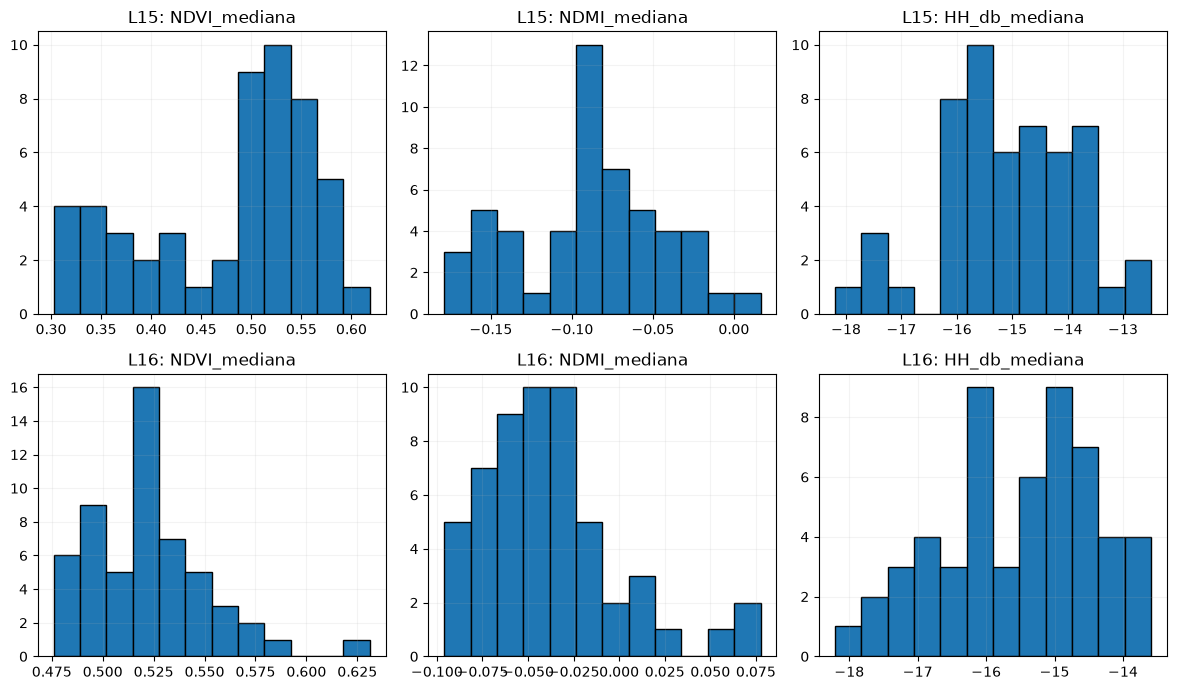

NDVI_mediana                                                   \
               count   mean    std    min    25%    50%    75%    max   
lote_id                                                                 
L15             52.0  0.478  0.085  0.302  0.411  0.507  0.541  0.618   
L16             55.0  0.523  0.030  0.476  0.500  0.519  0.538  0.631   

        NDVI_std         ... VV_db_mediana         VV_db_std                \
           count   mean  ...           75%     max     count   mean    std   
lote_id                  ...                                                 
L15         52.0  0.198  ...       -14.290 -12.727      52.0  3.203  0.812   
L16         55.0  0.186  ...       -14.873 -13.522      55.0  3.396  0.989   

                                            
           min    25%    50%    75%    max  
lote_id                                     
L15      1.155  2.702  3.229  3.648  6.346  
L16      1.876  2.816  3.273  3.746  6.527  

[2 rows x 112 columns]

L15 valores fuera de 1.5 IQR: 13
L16 valores fuera de 1.5 IQR: 31


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for fila, lote in enumerate(["L15", "L16"]):
    sub = datos[datos["lote_id"] == lote]

    for columna, variable in enumerate([
        "NDVI_mediana", "NDMI_mediana", "HH_db_mediana"
    ]):
        axes[fila, columna].hist(
            sub[variable], bins=12, edgecolor="black"
        )
        axes[fila, columna].set_title(f"{lote}: {variable}")
        axes[fila, columna].grid(alpha=0.15)

plt.tight_layout()
plt.show()

display(
    datos.groupby("lote_id")[
        opticas + radar
    ].describe().round(3)
)

for lote in ["L15", "L16"]:
    sub = datos[datos["lote_id"] == lote]
    q1 = sub[opticas + radar].quantile(0.25)
    q3 = sub[opticas + radar].quantile(0.75)
    iqr = q3 - q1
    atipicos = (
        (sub[opticas + radar] < q1 - 1.5 * iqr) |
        (sub[opticas + radar] > q3 + 1.5 * iqr)
    )
    print(lote, "valores fuera de 1.5 IQR:",
          int(atipicos.sum().sum()))


### 9.1.2. EDA complementario: distribuciones y correlaciones

Se amplian las comprobaciones descriptivas mediante
diagramas de cajas, matrices de correlacion y conteos
de valores faltantes.

Las correlaciones elevadas pueden revelar redundancia
entre atributos. Los valores extremos se identifican,
pero no se eliminan automaticamente porque pueden
reflejar variabilidad real o problemas de medicion.

El analisis se realiza por lote para evitar mezclar
distribuciones espaciales distintas.


Valores faltantes por atributo:


,faltantes
NDVI_mediana,0
NDVI_std,0
NDRE_mediana,0
NDRE_std,0
NDMI_mediana,0
NDMI_std,0
HH_db_mediana,0
HH_db_std,0
HV_db_mediana,0
HV_db_std,0


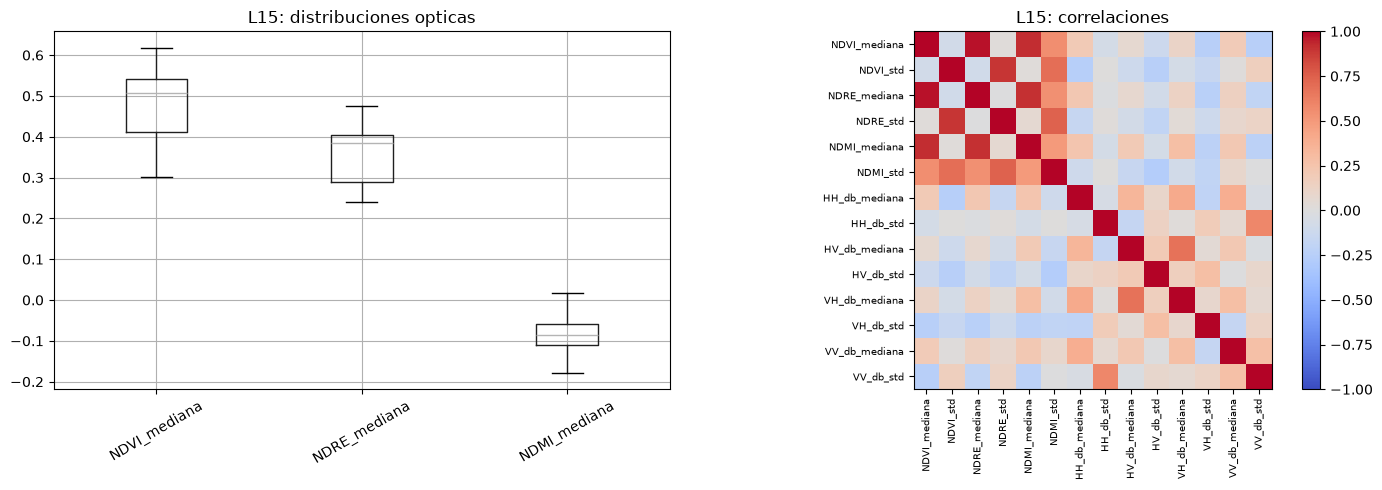

L15 - pares con correlacion absoluta >= 0.90: 3


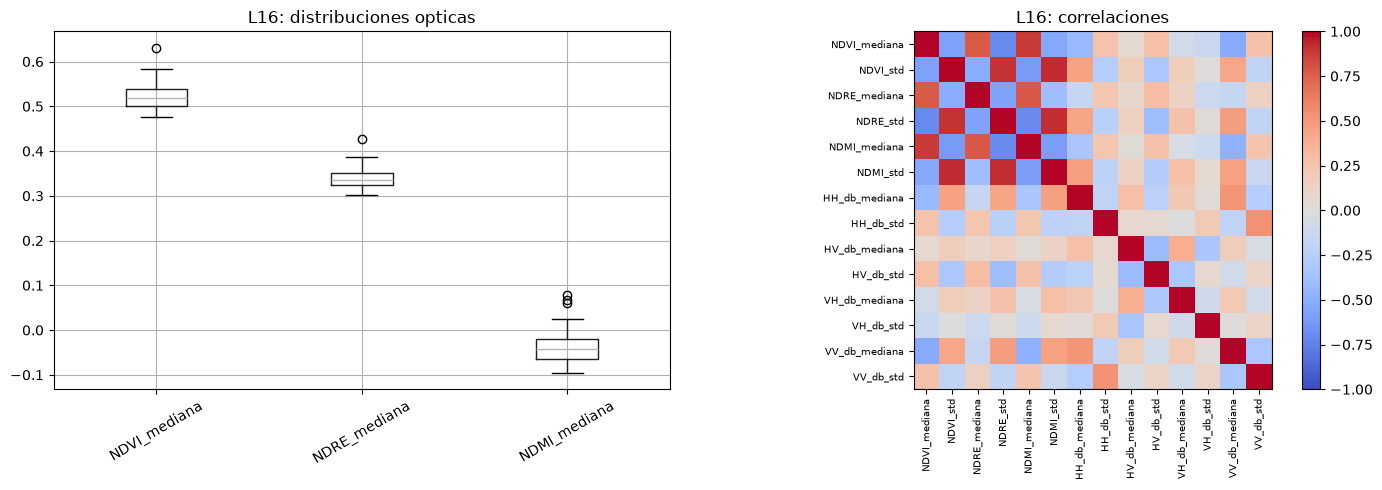

L16 - pares con correlacion absoluta >= 0.90: 3


In [11]:

variables_eda = opticas + radar

faltantes = (
    datos[variables_eda]
    .isna()
    .sum()
    .rename("faltantes")
    .to_frame()
)
print("Valores faltantes por atributo:")
display(faltantes)

for lote in ["L15", "L16"]:
    sub = datos.loc[
        datos["lote_id"] == lote,
        variables_eda
    ]

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5)
    )

    sub.boxplot(
        column=[
            "NDVI_mediana",
            "NDRE_mediana",
            "NDMI_mediana"
        ],
        ax=axes[0]
    )
    axes[0].set_title(
        f"{lote}: distribuciones opticas"
    )
    axes[0].tick_params(
        axis="x", rotation=30
    )

    correlaciones = sub.corr()
    imagen = axes[1].imshow(
        correlaciones,
        vmin=-1,
        vmax=1,
        cmap="coolwarm"
    )
    axes[1].set_xticks(
        range(len(variables_eda))
    )
    axes[1].set_yticks(
        range(len(variables_eda))
    )
    axes[1].set_xticklabels(
        variables_eda, rotation=90,
        fontsize=7
    )
    axes[1].set_yticklabels(
        variables_eda, fontsize=7
    )
    axes[1].set_title(
        f"{lote}: correlaciones"
    )
    fig.colorbar(
        imagen, ax=axes[1],
        fraction=0.046
    )
    plt.tight_layout()
    plt.show()

    pares = correlaciones.abs().where(
        np.triu(
            np.ones(
                correlaciones.shape,
                dtype=bool
            ),
            k=1
        )
    )

    print(
        lote,
        "- pares con correlacion absoluta >= 0.90:",
        int((pares >= 0.90).sum().sum())
    )


### 9.2. Comparación reproducible de clasificadores

Se utiliza validación cruzada estratificada repetida para comparar:

1. Regresión logística regularizada.
2. Random Forest.
3. XGBoost.

El escalado se ajusta dentro de cada partición de entrenamiento.

La validación cruzada estratificada no elimina la dependencia
espacial entre celdas vecinas. La evaluación espacial exploratoria
se presenta en una sección anterior del notebook.


,lote,variables,modelo,BA,F1_macro,BA_std
0,L15,Optico,Logistica,1.000,1.000,0.000
1,L15,Optico,RandomForest,1.000,1.000,0.000
2,L15,Optico,XGBoost,0.982,0.971,0.028
3,L15,Multisensor,Logistica,0.991,0.985,0.017
4,L15,Multisensor,RandomForest,0.986,0.978,0.019
5,L15,Multisensor,XGBoost,0.982,0.971,0.028
6,L16,Optico,Logistica,1.000,1.000,0.000
7,L16,Optico,RandomForest,0.962,0.945,0.078
8,L16,Optico,XGBoost,0.889,0.919,0.124
9,L16,Multisensor,Logistica,1.000,1.000,0.000


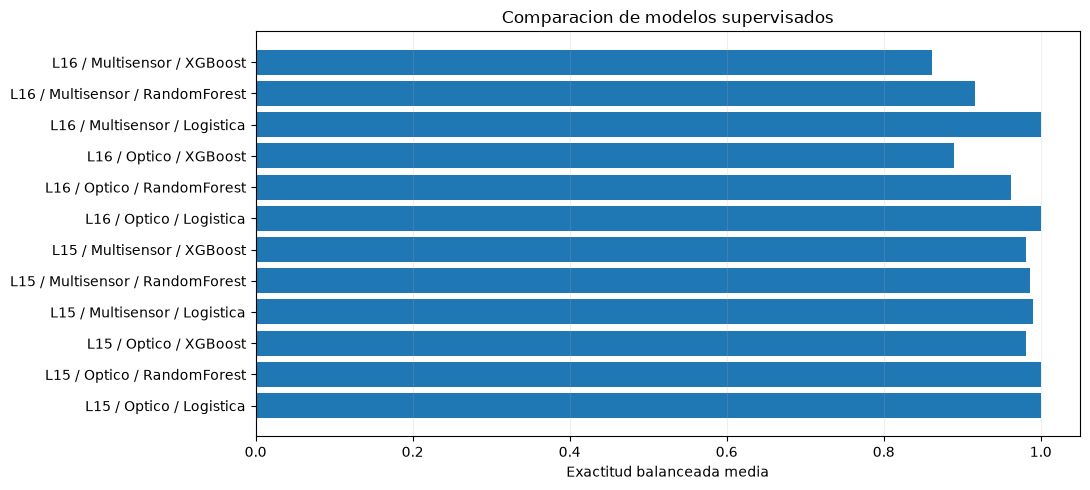

In [12]:
resultados_ml = []

for lote in ["L15", "L16"]:
    sub = datos[datos["lote_id"] == lote].copy()
    y = (sub["cluster_optico_intralote"].to_numpy()
         == sorted(sub["cluster_optico_intralote"].unique())[1]).astype(int)

    cv = RepeatedStratifiedKFold(
        n_splits=3, n_repeats=3, random_state=42
    )

    modelos = {
        "Logistica": Pipeline([
            ("escala", StandardScaler()),
            ("modelo", LogisticRegression(
                C=1.0, class_weight="balanced",
                max_iter=3000, random_state=42
            ))
        ]),
        "RandomForest": RandomForestClassifier(
            n_estimators=120, min_samples_leaf=2,
            class_weight="balanced", random_state=42,
            n_jobs=1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=100, max_depth=2,
            learning_rate=0.05, subsample=0.9,
            colsample_bytree=0.9,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42, n_jobs=1
        )
    }

    for conjunto, variables in conjuntos.items():
        X = sub[variables].to_numpy(dtype=float)

        for nombre, modelo in modelos.items():
            scores = cross_validate(
                modelo, X, y, cv=cv,
                scoring={
                    "ba": "balanced_accuracy",
                    "f1": "f1_macro"
                },
                n_jobs=1
            )

            resultados_ml.append({
                "lote": lote,
                "variables": conjunto,
                "modelo": nombre,
                "BA": scores["test_ba"].mean(),
                "F1_macro": scores["test_f1"].mean(),
                "BA_std": scores["test_ba"].std()
            })

resultados_ml = pd.DataFrame(resultados_ml)
display(resultados_ml.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
grafico = resultados_ml.copy()
grafico["configuracion"] = (
    grafico["lote"] + " / " +
    grafico["variables"] + " / " +
    grafico["modelo"]
)
ax.barh(grafico["configuracion"], grafico["BA"])
ax.set_xlim(0, 1.05)
ax.set_xlabel("Exactitud balanceada media")
ax.set_title("Comparacion de modelos supervisados")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### 9.3. Optimización de XGBoost

Se aplica `GridSearchCV` con validación estratificada.

La búsqueda se realiza para cada lote usando variables ópticas,
que constituyen la referencia principal del análisis.

Los resultados de la búsqueda describen el ajuste a
pseudoetiquetas; la mejor puntuación interna no representa
una evaluación externa independiente.


In [13]:
optimizacion_xgb = []
modelos_xgb = {}

for lote in ["L15", "L16"]:
    sub = datos[datos["lote_id"] == lote]
    clases = sorted(sub["cluster_optico_intralote"].unique())
    y = (sub["cluster_optico_intralote"].to_numpy()
         == clases[1]).astype(int)
    X = sub[opticas].to_numpy(dtype=float)

    estimador = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )

    busqueda = GridSearchCV(
        estimador,
        param_grid={
            "n_estimators": [50, 100],
            "max_depth": [2, 3],
            "learning_rate": [0.05, 0.1],
            "min_child_weight": [1, 3]
        },
        scoring="balanced_accuracy",
        cv=StratifiedKFold(
            n_splits=3, shuffle=True, random_state=42
        ),
        n_jobs=1,
        refit=True
    )

    busqueda.fit(X, y)
    modelos_xgb[lote] = (
        busqueda.best_estimator_, X, y
    )

    optimizacion_xgb.append({
        "lote": lote,
        "BA_CV_interna": busqueda.best_score_,
        "parametros": str(busqueda.best_params_)
    })

display(pd.DataFrame(optimizacion_xgb))

,lote,BA_CV_interna,parametros
0,L15,0.987179,"{'learning_rate': 0.05, 'max_depth': 2, 'min_c..."
1,L16,0.916667,"{'learning_rate': 0.05, 'max_depth': 2, 'min_c..."


### 9.4. Interpretabilidad SHAP de XGBoost

Se calcula la contribución de cada atributo a la salida del
modelo XGBoost ajustado.

El gráfico representa importancia estadística para reproducir
pseudoetiquetas ópticas, no efectos causales sobre el cultivo.

El modelo se ajusta sobre todas las celdas de cada lote para
su interpretación descriptiva.



Importancia SHAP: L15


,variable,SHAP_absoluto_medio
0,NDVI_mediana,2.4251
1,NDVI_std,0.0000
2,NDRE_mediana,0.0000
3,NDRE_std,0.0000
4,NDMI_mediana,0.0000
5,NDMI_std,0.0000


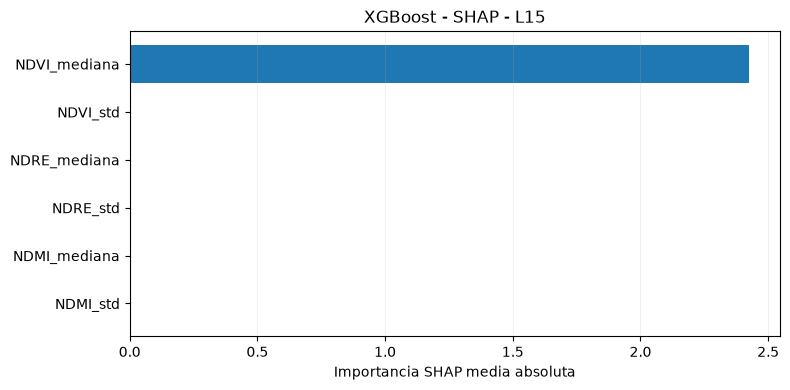


Importancia SHAP: L16


,variable,SHAP_absoluto_medio
5,NDMI_std,1.7469
1,NDVI_std,0.1409
3,NDRE_std,0.0500
0,NDVI_mediana,0.0000
2,NDRE_mediana,0.0000
4,NDMI_mediana,0.0000


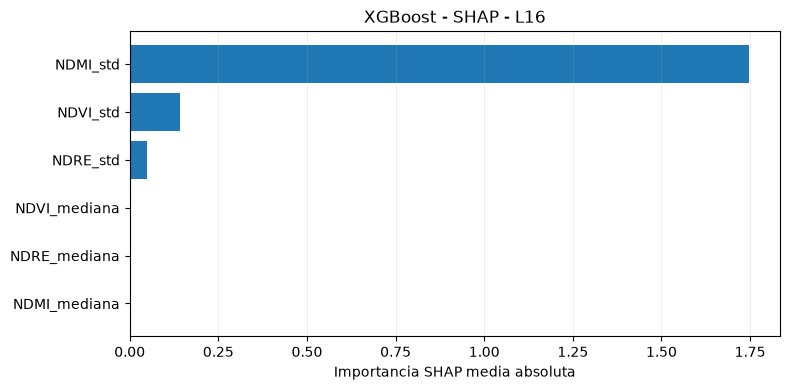

In [14]:
for lote in ["L15", "L16"]:
    modelo, X, y = modelos_xgb[lote]

    explicador = shap.TreeExplainer(modelo)
    valores = explicador.shap_values(X)
    valores = np.asarray(valores)

    if valores.ndim == 3:
        valores = valores[:, :, -1]

    importancia = np.abs(valores).mean(axis=0)

    ranking = pd.DataFrame({
        "variable": opticas,
        "SHAP_absoluto_medio": importancia
    }).sort_values(
        "SHAP_absoluto_medio", ascending=False
    )

    print("\nImportancia SHAP:", lote)
    display(ranking.round(4))

    fig, ax = plt.subplots(figsize=(8, 4))
    orden = ranking.iloc[::-1]
    ax.barh(
        orden["variable"],
        orden["SHAP_absoluto_medio"]
    )
    ax.set_title(f"XGBoost - SHAP - {lote}")
    ax.set_xlabel("Importancia SHAP media absoluta")
    ax.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()

### 9.5. Interpretación de los resultados

La comparación de modelos permite estudiar qué algoritmos
reproducen mejor los agrupamientos exploratorios.

Una puntuación elevada no demuestra que las clases
correspondan a ambientes productivos reales.

La incorporación de SAOCOM debe evaluarse por separado
en dos dimensiones:

- **Complementariedad observacional:** disponibilidad de
  observaciones radar sin pareja óptica cercana.
- **Mejora predictiva:** diferencias de desempeño al
  comparar modelos con el mismo objetivo y particiones.

Los resultados del proyecto muestran complementariedad
observacional, pero no una mejora predictiva multisensor
consistente.

La validación agronómica requerirá información independiente
de suelo, rendimiento, biomasa o manejo y nuevas campañas.



### 9.6. Seleccion comparativa de modelos

Se comparan las configuraciones evaluadas mediante
validacion cruzada estratificada repetida.

El criterio principal es la **exactitud balanceada
media**, apropiada cuando las clases tienen
diferentes cantidades de observaciones.

Como criterios secundarios se consideran:

1. F1 macro.
2. Desviacion estandar de la exactitud balanceada.
3. Simplicidad del algoritmo.
4. Cantidad de familias de sensores necesarias.

La seleccion es **exploratoria**. No constituye
una estimacion insesgada del rendimiento del
modelo elegido, porque se realiza utilizando
los resultados de validacion disponibles.

Las metricas reflejan la reproduccion de
pseudoetiquetas y no la prediccion de rendimiento
o productividad agricola.


In [15]:

comparativa = resultados_ml.copy()

orden_simplicidad = {
    "Logistica": 0,
    "RandomForest": 1,
    "XGBoost": 2
}

comparativa["complejidad"] = (
    comparativa["modelo"]
    .map(orden_simplicidad)
)

comparativa["sensores_adicionales"] = (
    comparativa["variables"]
    .ne("Optico")
    .astype(int)
)

comparativa = comparativa.sort_values(
    [
        "lote",
        "BA",
        "F1_macro",
        "BA_std",
        "complejidad",
        "sensores_adicionales"
    ],
    ascending=[
        True, False, False,
        True, True, True
    ]
)

seleccion = (
    comparativa
    .groupby("lote", as_index=False)
    .head(1)
    .copy()
)

print("Comparacion completa:")
display(
    comparativa[
        [
            "lote", "variables", "modelo",
            "BA", "F1_macro", "BA_std"
        ]
    ].round(3)
)

print("Mejor configuracion exploratoria por lote:")
display(
    seleccion[
        [
            "lote", "variables", "modelo",
            "BA", "F1_macro", "BA_std"
        ]
    ].round(3)
)

print(
    "Advertencia: seleccion descriptiva "
    "sobre validacion cruzada disponible; "
    "no es una prueba externa independiente."
)


Comparacion completa:


,lote,variables,modelo,BA,F1_macro,BA_std
0,L15,Optico,Logistica,1.000,1.000,0.000
1,L15,Optico,RandomForest,1.000,1.000,0.000
3,L15,Multisensor,Logistica,0.991,0.985,0.017
4,L15,Multisensor,RandomForest,0.986,0.978,0.019
2,L15,Optico,XGBoost,0.982,0.971,0.028
5,L15,Multisensor,XGBoost,0.982,0.971,0.028
6,L16,Optico,Logistica,1.000,1.000,0.000
9,L16,Multisensor,Logistica,1.000,1.000,0.000
7,L16,Optico,RandomForest,0.962,0.945,0.078
10,L16,Multisensor,RandomForest,0.917,0.939,0.118


Mejor configuracion exploratoria por lote:


,lote,variables,modelo,BA,F1_macro,BA_std
0,L15,Optico,Logistica,1.0,1.0,0.0
6,L16,Optico,Logistica,1.0,1.0,0.0


Advertencia: seleccion descriptiva sobre validacion cruzada disponible; no es una prueba externa independiente.



## 10. Evaluacion final y conclusiones integradas

### 10.1. Respuesta al problema planteado

El proyecto demuestra la factibilidad metodologica de
integrar informacion optica Sentinel-2 y radar SAOCOM
para explorar la heterogeneidad espacial de dos lotes
asociados al cultivo de maiz para silo forrajero en
el establecimiento La Rosaura.

La tarea supervisada se formula como una clasificacion
de pseudoetiquetas generadas previamente mediante
KMeans. Por lo tanto, la variable objetivo no representa
rendimiento observado ni una clasificacion agronomica
independiente.

### 10.2. Principales resultados

**Integracion de datos.** Se analizaron 107 celdas
espaciales: 52 en L15 y 55 en L16. La grilla comun
permitio comparar atributos opticos y radar.

**Complementariedad temporal.** Se identificaron
294 observaciones celda-fecha radar sin pareja
optica valida dentro de una ventana de cinco dias,
sobre 1.391 observaciones radar consideradas
(21,1 %). Esto respalda una ventaja observacional,
sin implicar cobertura continua.

**Agrupamientos exploratorios.** Las configuraciones
optica y multisensor coincidieron en 106 de 107
celdas. La elevada concordancia muestra que la
incorporacion de radar no altero sustancialmente
la particion obtenida en estos dos lotes.

**Clasificacion supervisada.** Se compararon
regresion logistica, Random Forest y XGBoost
utilizando exactitud balanceada y F1 macro.
Se aplico GridSearchCV a XGBoost. La seleccion
de configuraciones se presenta en la seccion 9.6.
Las puntuaciones describen reproduccion de
pseudoetiquetas, no capacidad predictiva agricola.

**Explicabilidad.** Los analisis SHAP permiten
identificar los atributos que mas contribuyen
a las predicciones de los modelos ajustados.
No prueban relaciones causales entre indices
satelitales y productividad del maiz.

### 10.3. Evaluacion de las hipotesis

- **H1:** la complementariedad observacional
  esta respaldada descriptivamente.
- **H2:** se observaron senales de naturaleza
  diferente, pero no se demostro utilidad
  agronomica adicional.
- **H3:** no se demostro una mejora consistente
  en la delimitacion de ambientes mediante radar.
- **H4:** la estabilidad interanual permanece
  sin evaluar.

### 10.4. Relevancia para La Rosaura

El aporte potencial es metodologico: establecer
un procedimiento reproducible que podria servir
como base para analizar variabilidad intralote
en cultivos destinados a reservas forrajeras.

No corresponde recomendar fertilizacion
diferenciada, cambios de manejo ni decisiones
productivas concretas a partir de los grupos
identificados en esta etapa.

### 10.5. Limitaciones y continuidad

El estudio abarca solamente dos lotes y una
campaña historica. No dispone de datos
independientes de rendimiento, suelo, biomasa
o manejo. Ademas, existen dependencia espacial
entre celdas y limitaciones de calibracion radar.

Una etapa futura deberia incorporar mediciones
de campo, nuevas campañas y evaluacion espacial
independiente predefinida, para determinar si
los agrupamientos tienen utilidad agronomica real.

**Conclusion general:** la integracion multisensor
resulta factible y amplía las oportunidades de
observacion, pero los resultados disponibles no
permiten afirmar que SAOCOM mejore la prediccion
o delimitacion de ambientes de manejo validados.
